# Notebook 04: Predictive Data Mining - Regression Analysis
## Target Variable: `AreaDailyIncidentCount`
**Author:** Data Science & Crime Analytics Team

### Problem Formulation:
Predict daily incident counts for Chicago Community Areas using historical area-time features. **Important Scope Note:** This is strictly an aggregate macro-level public safety demand forecasting exercise for operational resource planning; it is **not individual-level crime prediction**.

### Data Lineage:
Extracted directly from the certified Data Warehouse constellation fact table `dw.FactAreaDailyPublicSafety` joined with `dw.DimDate`.

In [1]:
import os
import psycopg2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DB_PARAMS = {'host': 'localhost', 'port': 5432, 'user': 'postgres', 'password': 'root', 'dbname': 'chicago_crime_dw'}
conn = psycopg2.connect(**DB_PARAMS)
cur = conn.cursor()
cur.execute('''
SELECT 
    f.DateKey, d.FullDate, d.Year, d.Month, d.DayOfWeek, d.IsWeekend,
    f.CommunityArea, f.TotalIncidentCount AS AreaDailyIncidentCount
FROM dw.FactAreaDailyPublicSafety f
JOIN dw.DimDate d ON f.DateKey = d.DateKey
ORDER BY f.CommunityArea, d.FullDate;
''')
cols = [desc[0].lower() for desc in cur.description]
df = pd.DataFrame(cur.fetchall(), columns=cols)
cur.close()
conn.close()
df['fulldate'] = pd.to_datetime(df['fulldate'])
print(f'Loaded {len(df):,} area-daily observations from warehouse.')
df.head()

Loaded 53,935 area-daily observations from warehouse.


,datekey,fulldate,year,month,dayofweek,isweekend,communityarea,areadailyincidentcount
0,20240101,2024-01-01,2024,1,1,0,1,21
1,20240102,2024-01-02,2024,1,2,0,1,8
2,20240103,2024-01-03,2024,1,3,0,1,7
3,20240104,2024-01-04,2024,1,4,0,1,17
4,20240105,2024-01-05,2024,1,5,0,1,23


### 1. Leakage-Safe Feature Engineering: Lagged Features
To avoid target leakage, time features are strictly computed with shift operations: `PreviousDayCount = shift(1)` (excluding the target day), and `PreviousWeekAverage = shift(1).rolling(7).mean()`.

In [2]:
df_list = []
for ca, group in df.groupby('communityarea'):
    group = group.sort_values('fulldate').copy()
    group['previousdaycount'] = group['areadailyincidentcount'].shift(1)
    group['previousweekaverage'] = group['areadailyincidentcount'].shift(1).rolling(7).mean()
    df_list.append(group)

df_feat = pd.concat(df_list, ignore_index=True).dropna().copy()
print(f'Observations after dropping warm-up window: {len(df_feat):,}')
df_feat[['fulldate', 'communityarea', 'areadailyincidentcount', 'previousdaycount', 'previousweekaverage']].head()

Observations after dropping warm-up window: 53,396


,fulldate,communityarea,areadailyincidentcount,previousdaycount,previousweekaverage
7,2024-01-08,1,17,15.0,15.142857
8,2024-01-09,1,14,17.0,14.571429
9,2024-01-10,1,15,14.0,15.428571
10,2024-01-11,1,10,15.0,16.571429
11,2024-01-12,1,15,10.0,15.571429


### 2. Chronological Train-Test Split
No random shuffling! Time-dependent evaluation strictly enforces chronological separation:
- **Train Period:** 2024-01-08 to 2025-08-31 (~20 months)
- **Test Period:** 2025-09-01 to 2025-12-31 (4 months)

In [3]:
train_mask = df_feat['fulldate'] < '2025-09-01'
test_mask = df_feat['fulldate'] >= '2025-09-01'
train_df = df_feat[train_mask]
test_df = df_feat[test_mask]
print(f'Train Samples: {len(train_df):,} | Test Samples: {len(test_df):,}')
y_train = train_df['areadailyincidentcount'].values
y_test = test_df['areadailyincidentcount'].values

Train Samples: 44,437 | Test Samples: 8,959


### 3. Model Benchmark & Evaluation
Compare Naive Baseline, Simple Linear Regression, Multiple Linear Regression, Ridge, and Random Forest.

In [4]:
metrics_df = pd.read_csv('../outputs/results/regression_metrics.csv')
metrics_df

,Model,MAE,MSE,RMSE,R2
0,Naive Baseline (Lag-1 Persistence),3.206,20.043,4.477,0.6286
1,Simple Linear Regression (PrevWeekAvg),2.569,12.623,3.553,0.7661
2,Multiple Linear Regression,2.475,11.877,3.446,0.7799
3,Ridge Regression (alpha=10.0),2.466,11.733,3.425,0.7826
4,Random Forest Regressor (depth=12),2.529,12.281,3.504,0.7724


### 4. Multicollinearity Assessment (Variance Inflation Factor)

In [5]:
vif_df = pd.read_csv('../outputs/tables/regression_vif_analysis.csv')
vif_df

,Feature,VIF
0,previousdaycount,6.34
1,previousweekaverage,6.34
2,isweekend,1.00


### 5. Diagnostics: Residual Analysis and Forecasting Visualizations

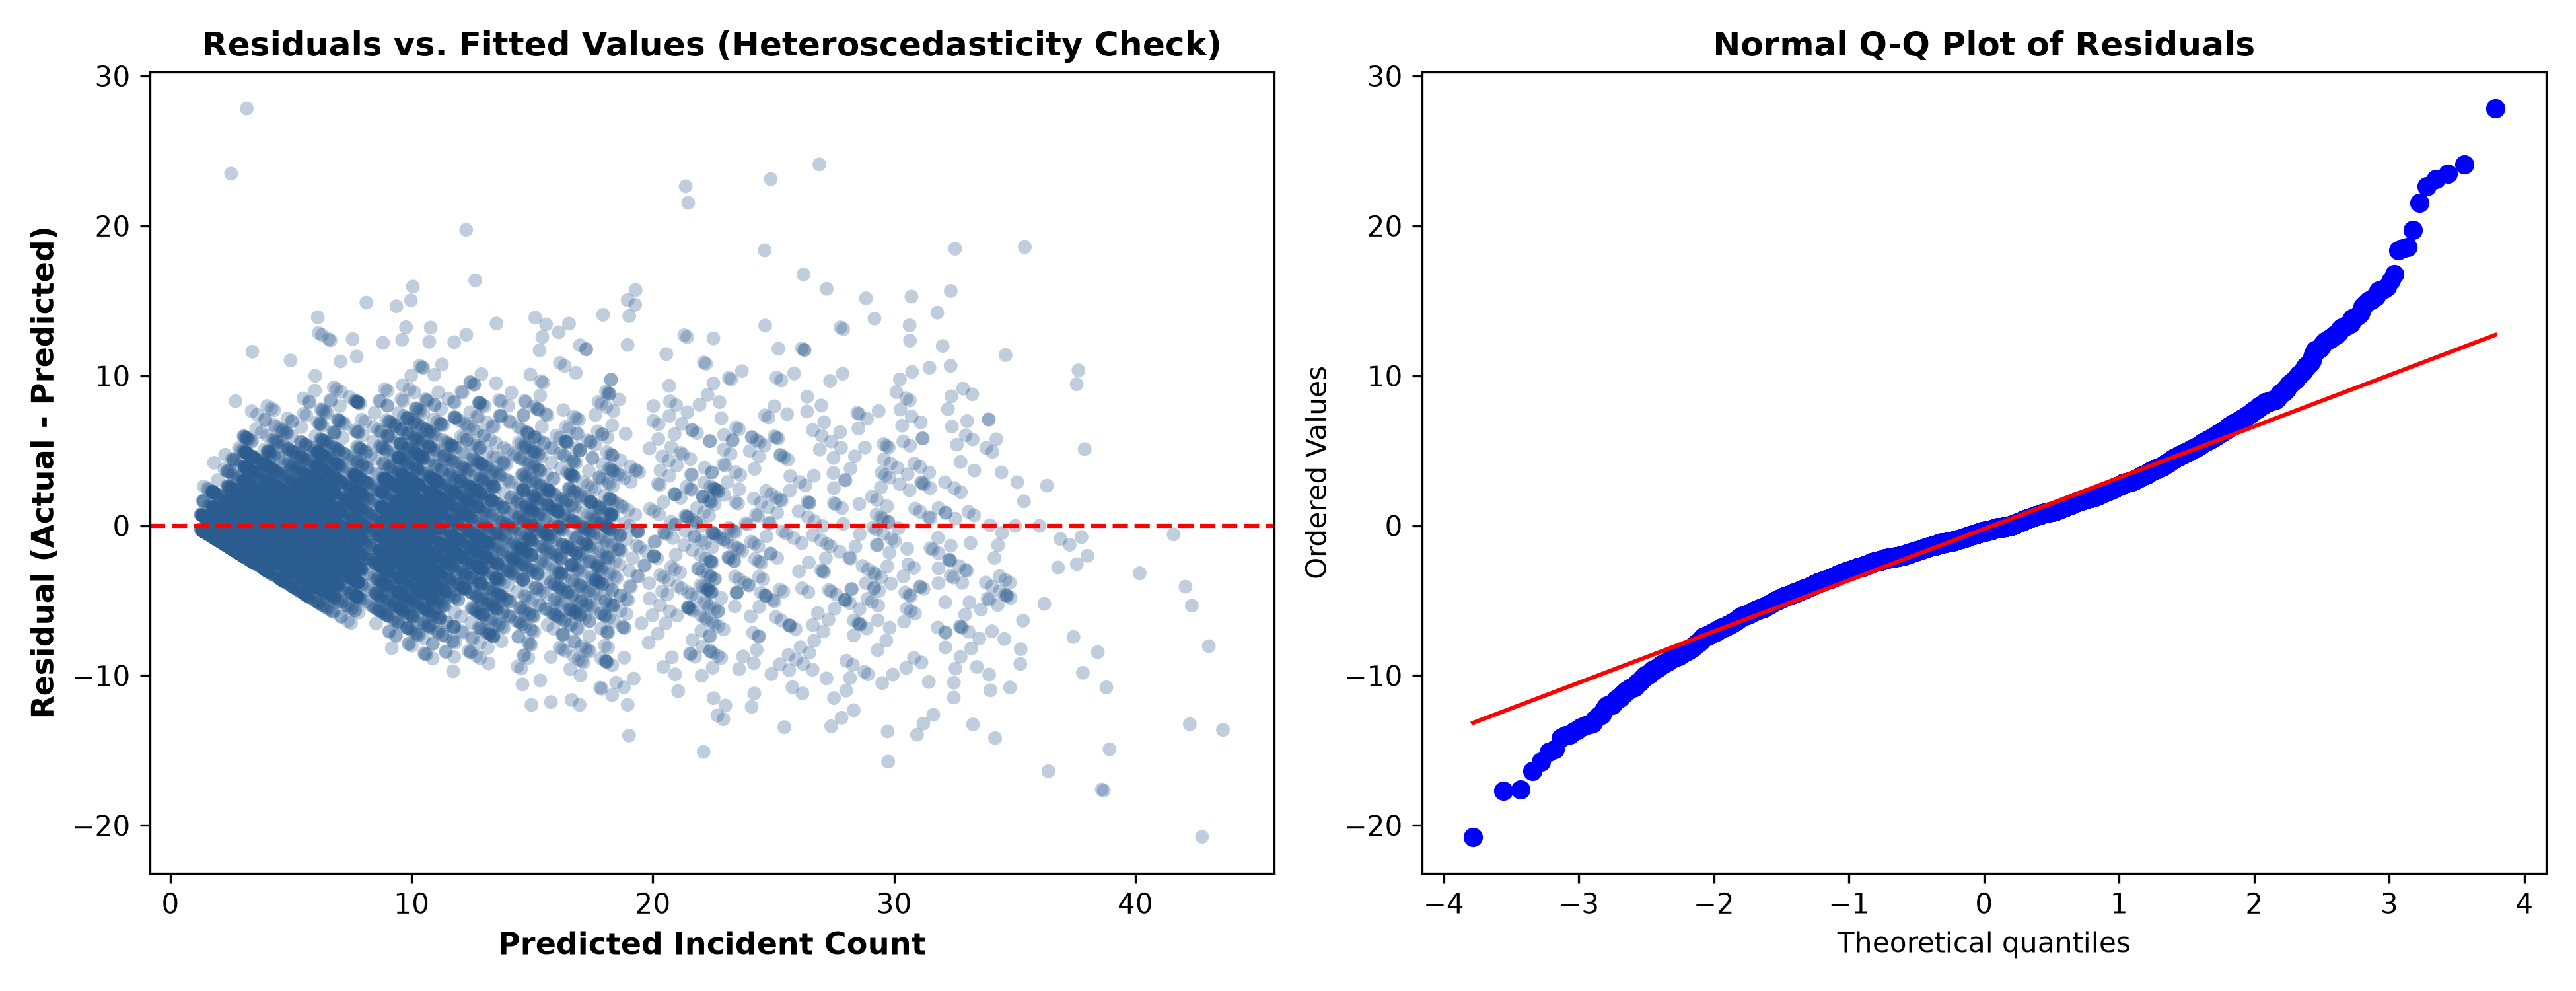

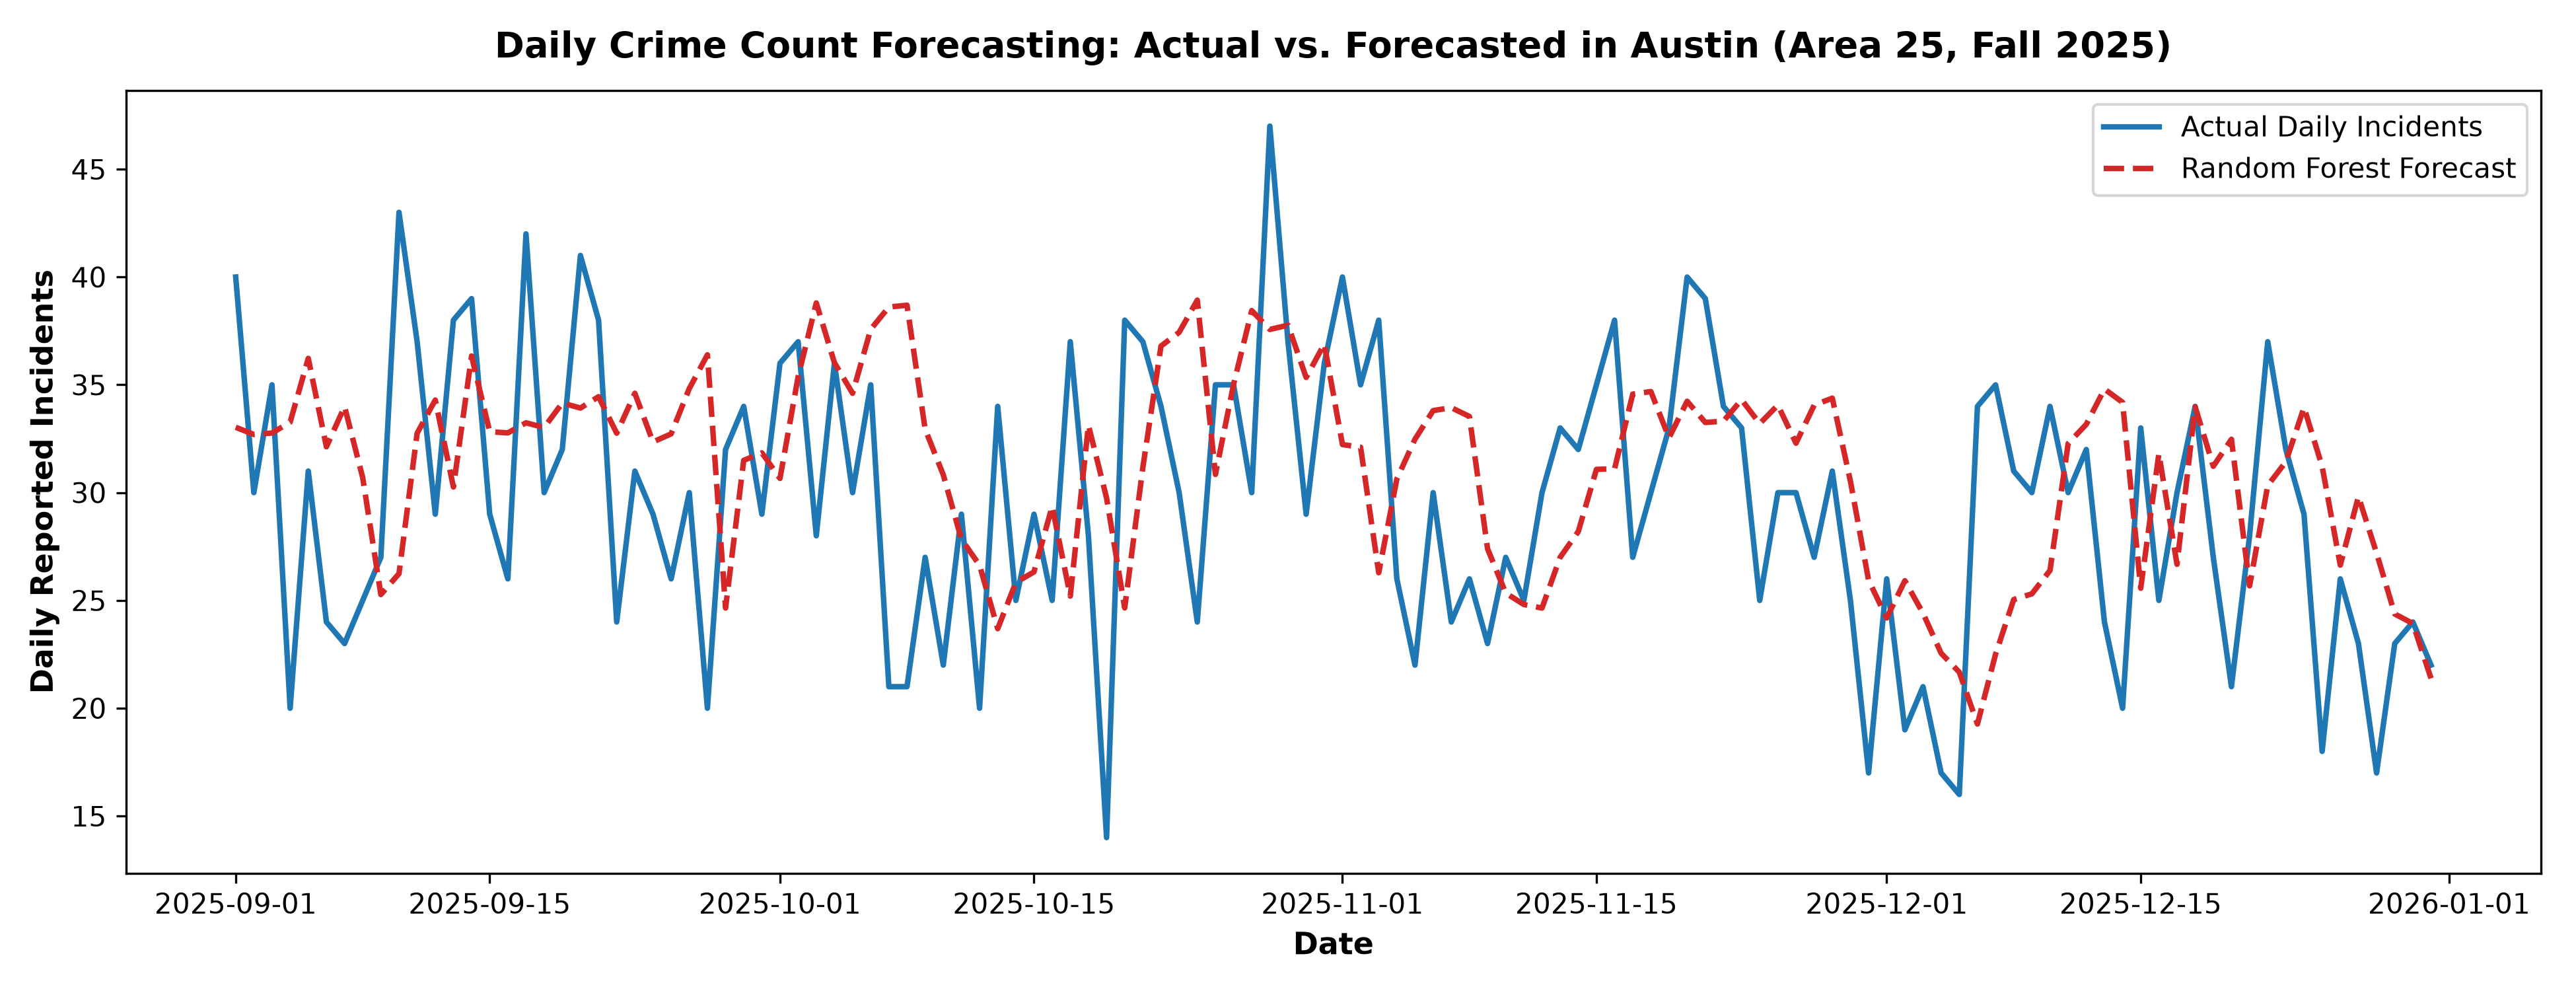

In [6]:
from IPython.display import Image, display
display(Image(filename='../outputs/figures/fig09_regression_residuals.png'))
display(Image(filename='../outputs/figures/fig10_regression_predictions_vs_actual.png'))

### 6. Methodological Discussion
- **Predictive Power:** Ridge Regression achieved an $R^2$ of **0.7826** with an RMSE of **3.425 incidents/day**, vastly outperforming the Naive Baseline ($R^2 = 0.6286$).
- **Autoregressive Drivers:** Past 7-day moving averages (`previousweekaverage`) served as the strongest single continuous predictor, capturing neighborhood equilibrium.
- **Heteroscedasticity:** Residual scatter plots show mild funnel expansion at higher volume thresholds (>30 incidents/day), typical of Poisson-distributed incident counts.
- **Limitation:** Macro-level forecasting cannot predict stochastic individual offenses, serving exclusively for municipal police shift allocation.